In [36]:
import numpy as np
import matplotlib.pyplot as plt

El valor de la intensidad específica al final del intervalo (tau = 5) es de I = -10.0470.


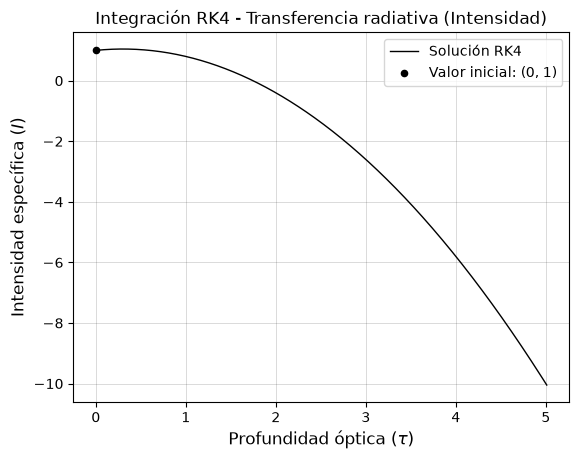

In [39]:
# TRANSFERENCIA RADIATIVA

# ----------------- Parámetros del sistema -----------------

S = 0.3 # Función fuente

def f(I, tau):
    return -I + S

# ----------------- Parámetros de solución -----------------

tau_span = [0, 5]
I0 = 1
h = 0.01

# ----------------- Implementación Método RK4 -----------------

def rk4_step(t_i, x_i, f, h):

    k1 = f(t_i, x_i)
    k2 = f(t_i + h/2, x_i + k1*h/2)
    k3 = f(t_i + h/2, x_i + k2*h/2)
    k4 = f(t_i + h, x_i + k3*h)

    return x_i + (h/6)*(k1 + 2*k2 + 2*k3 + k4)

def rk4(x_start, t_start, t_end, f, h, max_steps=1e4):

    t_arr = [t_start]
    x_arr = [x_start]

    while (t_arr[-1] < t_end) and (len(x_arr) < max_steps):
        x_next = rk4_step(t_arr[-1], x_arr[-1], f, h)
        t_next = t_arr[-1] + h

        t_arr.append(t_next)
        x_arr.append(x_next)

    t_arr = np.array(t_arr)
    x_arr = np.array(x_arr)

    return t_arr, x_arr 

tau_num, I_num = rk4(I0, tau_span[0], tau_span[1], f, h)

# ----------------- Valores finales -----------------

print(f'El valor de la intensidad específica al final del intervalo (tau = {tau_span[1]}) es de I = {I_num[-1]:.4f}.')

plt.plot(tau_num, I_num, color='k', lw=1, label='Solución RK4')
plt.scatter(tau_span[0], I0, color='k', s=20, label=f'Valor inicial: ({tau_span[0]}, {I0})')

plt.grid(color='k', lw=0.5, alpha=0.2)
plt.xlabel(r'Profundidad óptica ($\tau$)', fontsize=12)
plt.ylabel(r'Intensidad específica ($I$)', fontsize=12)
plt.title('Integración RK4 - Transferencia radiativa (Intensidad)')
plt.legend()
plt.show()